# Vẽ Ảnh Bàn Cờ Minh Họa Tùy Chỉnh (`ve_anh_custom.ipynb`)

Notebook này cung cấp các mẫu dựng hình bàn cờ trực quan bằng `render_board_image()` (`chess_ai/ui/board_renderer.py`, tái sử dụng bảng màu & bộ quân SVG của Pygame Desktop UI) phục vụ báo cáo và thuyết trình:
1. **Mục 1 — Minh họa Agent Level 1 (`Level1RandomAgent`):** Sinh thế cờ trung lập ngẫu nhiên (`SEED = 42`), vẽ toàn bộ không gian nước hợp lệ và nước được chọn ngẫu nhiên.
2. **Mục 2 — Minh họa Thế cờ Tùy chỉnh (`Custom FEN`):** Vẽ nhanh bất kỳ thế cờ nào kèm ô nhấn mạnh, mũi tên xanh (nước tối ưu/được chọn) và mũi tên đỏ (nước bẫy/sai lầm).
3. **Mục 3 — So sánh Trực quan Nhiều Agent trên cùng 1 Thế cờ:** Đặt `Level 1..4` cạnh nhau để đối chiếu quyết định.

In [21]:
from pathlib import Path
import random
import sys
from typing import Iterable, Optional

import chess
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.agents.registry import create_agent
from chess_ai.core.chess_env import ChessEnv
from chess_ai.ui.board_renderer import render_board_image

SEED = 40


def show_board(
    board: chess.Board,
    title: str = "",
    move: Optional[chess.Move] = None,
    moves: Optional[Iterable[chess.Move]] = None,
    bad_move: Optional[chess.Move] = None,
    highlight_squares: Optional[Iterable[int]] = None,
    board_size: int = 512,
    save_path: Optional[str] = None,
) -> None:
    """Hiển thị bàn cờ trong notebook và tùy chọn lưu thành ảnh PNG."""
    img = render_board_image(
        board,
        move=move,
        moves=moves,
        bad_move=bad_move,
        highlight_squares=highlight_squares,
        board_size=board_size,
    )
    fig, ax = plt.subplots(figsize=(6.0, 6.0), dpi=130)
    ax.imshow(img)
    if title:
        ax.set_title(title, fontsize=10)
    ax.axis("off")
    fig.tight_layout()
    if save_path:
        out = PROJECT_ROOT / save_path
        out.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"Đã lưu ảnh tại: {out}")
    plt.show()

## 1. Minh họa Agent Level 1 (`Level1RandomAgent`) trên Thế cờ Ngẫu nhiên

SEED: 40 | FEN: 4k3/2p2p2/1n6/4P3/2B2N2/8/4K3/3R4 w - - 0 1
Tổng nước hợp lệ: 37 (p = 0.0270) | Chọn: d1h1 (Rh1)


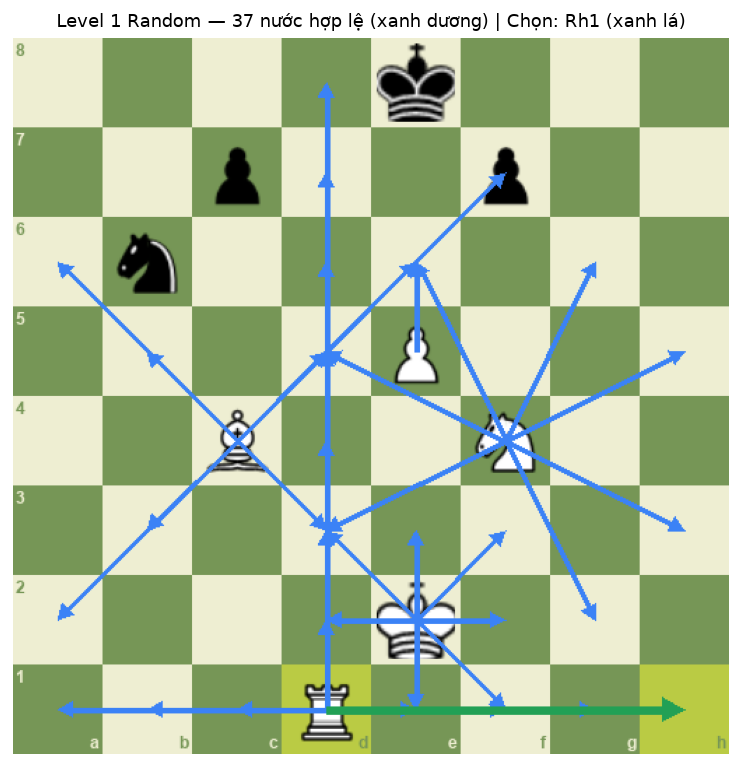

,STT,UCI,SAN,Xác suất,Chọn
0,1,f4g6,Ng6,0.027,
1,2,f4e6,Ne6,0.027,
2,3,f4h5,Nh5,0.027,
3,4,f4d5,Nd5,0.027,
4,5,f4h3,Nh3,0.027,
5,6,f4d3,Nd3,0.027,
6,7,f4g2,Ng2,0.027,
7,8,c4f7,Bxf7+,0.027,
8,9,c4e6,Be6,0.027,
9,10,c4a6,Ba6,0.027,


In [22]:
CUSTOM_FEN = "4k3/2p2p2/1n6/4P3/2B2N2/8/4K3/3R4 w - - 0 1"
env_l1 = ChessEnv(fen=CUSTOM_FEN)
agent_l1 = create_agent("level1", seed=SEED)

legal_moves = env_l1.legal_actions()
chosen_l1 = agent_l1.select_move(env_l1)
prob = 1.0 / len(legal_moves)

print(f"SEED: {SEED} | FEN: {CUSTOM_FEN}")
print(f"Tổng nước hợp lệ: {len(legal_moves)} (p = {prob:.4f}) | Chọn: {chosen_l1.uci()} ({env_l1.board.san(chosen_l1)})")

show_board(
    env_l1.board,
    title=f"Level 1 Random — {len(legal_moves)} nước hợp lệ (xanh dương) | Chọn: {env_l1.board.san(chosen_l1)} (xanh lá)",
    move=chosen_l1,
    moves=legal_moves,
)

df_l1 = pd.DataFrame([
    {"STT": i + 1, "UCI": m.uci(), "SAN": env_l1.board.san(m), "Xác suất": round(prob, 4), "Chọn": "✓" if m == chosen_l1 else ""}
    for i, m in enumerate(legal_moves)
])
display(df_l1)

## 2. Minh họa Thế cờ Tùy chỉnh (Dùng cho Báo cáo / Slide)

Thay `TARGET_FEN`, `GOOD_MOVE`, `BAD_MOVE`, `HIGHLIGHT_SQUARES` (và `SAVE_PATH` nếu muốn xuất file PNG).

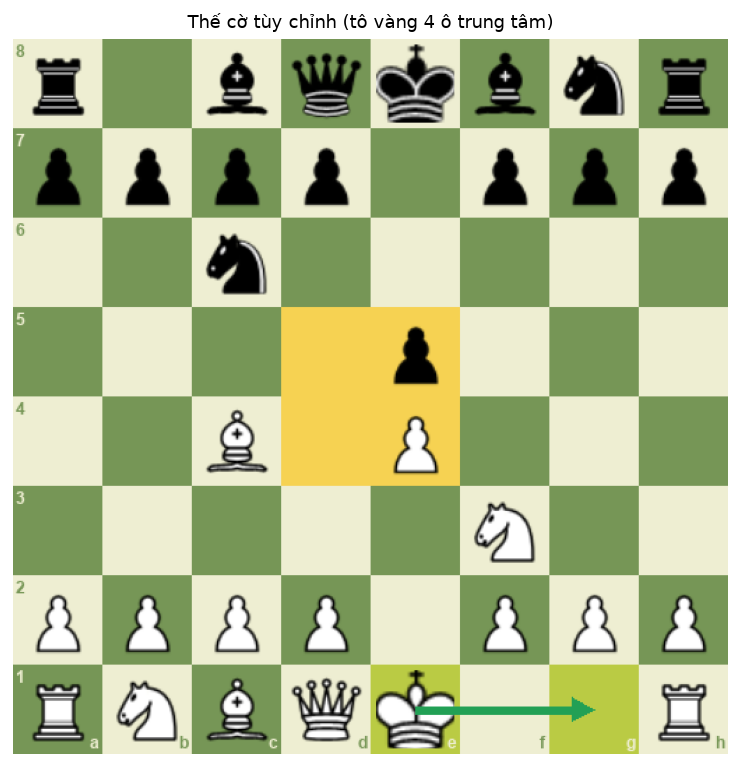

In [23]:
TARGET_FEN = "r1bqkbnr/pppp1ppp/2n5/4p3/2B1P3/5N2/PPPP1PPP/RNBQK2R w KQkq - 4 4"
GOOD_MOVE = chess.Move.from_uci("e1g1")   # Nhập thành an toàn
BAD_MOVE = None                           # Ví dụ: chess.Move.from_uci("f3g5")
HIGHLIGHT_SQUARES = (chess.D4, chess.D5, chess.E4, chess.E5)
SAVE_PATH = None                          # Ví dụ: "results/figures/custom_board.png"

custom_board = chess.Board(TARGET_FEN)
show_board(
    custom_board,
    title="Thế cờ tùy chỉnh (tô vàng 4 ô trung tâm)",
    move=GOOD_MOVE,
    bad_move=BAD_MOVE,
    highlight_squares=HIGHLIGHT_SQUARES,
    save_path=SAVE_PATH,
)

## 3. So sánh Trực quan Nhiều Agent trên cùng 1 Thế cờ

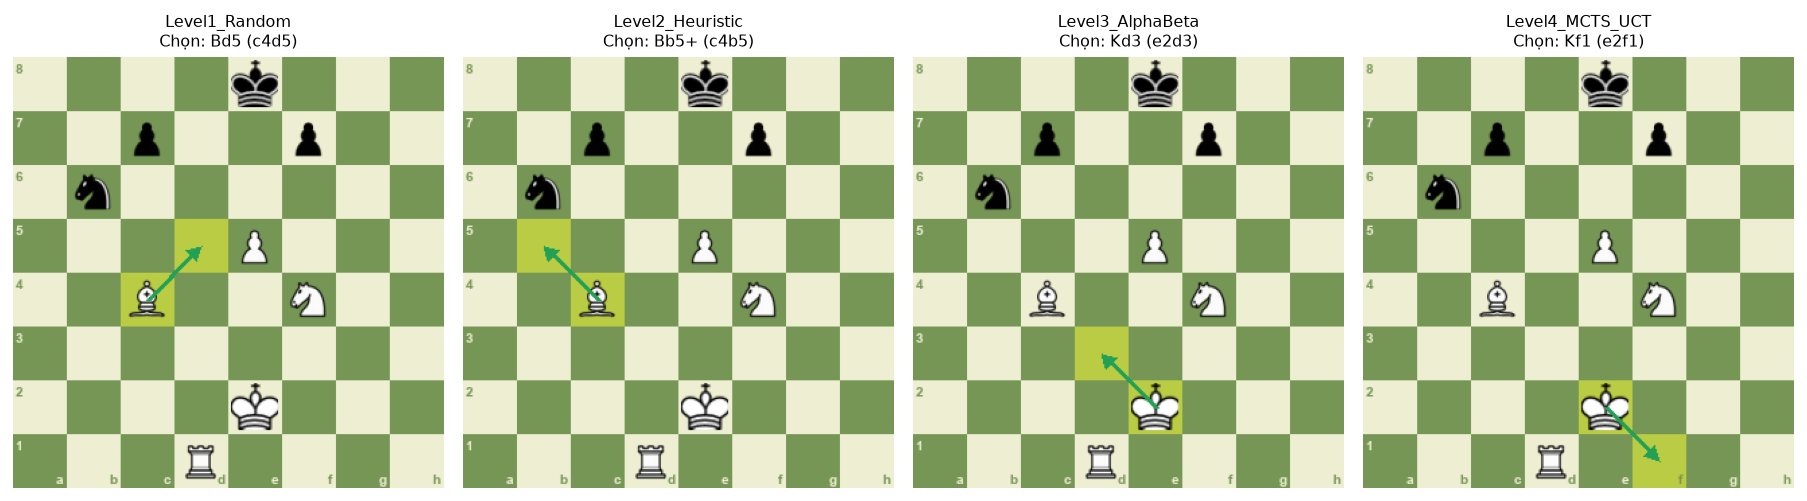

In [24]:
COMPARE_FEN = CUSTOM_FEN  # Dùng lại thế cờ ngẫu nhiên ở trên hoặc thay bằng FEN bất kỳ
AGENT_IDS = ["level1", "level2", "level3", "level4"]

fig, axes = plt.subplots(1, len(AGENT_IDS), figsize=(14, 3.8), dpi=130)
for ax, aid in zip(axes, AGENT_IDS):
    env_cmp = ChessEnv(fen=COMPARE_FEN)
    ag = create_agent(aid)
    m = ag.select_move(env_cmp, time_limit=0.5, max_workload=200)
    img = render_board_image(env_cmp.board, move=m, board_size=320)
    ax.imshow(img)
    ax.set_title(f"{ag.name}\nChọn: {env_cmp.board.san(m)} ({m.uci()})", fontsize=9)
    ax.axis("off")

fig.tight_layout()
plt.show()